# Onderdelenherkenning — werkende klassieke OpenCV-code op jouw dataset

Dit notebook is een omzetting van de aangeleverde werkende code. **De segmentatie op een effen achtergrond blijft ongewijzigd**. Het notebook leest foto's uit een instelbare datasetmap en gebruikt `data.yaml` **alleen voor de klassennamen**, niet voor detectie of training. Er worden geen annotatiebestanden gelezen.

**Let op:** jouw foto's bevatten een schaakbord; de oorspronkelijke segmentatie veronderstelt een lichte effen achtergrond. Daarom zijn foutieve detecties mogelijk. Test eerst één foto en bekijk het masker. De millimeterwaarden zijn alleen betrouwbaar als `PIXELS_PER_MM` voor jouw originele foto's is gekalibreerd.

In [13]:
from pathlib import Path
import math, random, re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# PAS DIT AAN als je dataset ergens anders staat.
DATASET_ROOT = Path("dataset")
REFERENTIE_PAD = Path("dataset/images/leeg_schaakbord.jpeg")
IMAGES_DIR = DATASET_ROOT / "images"
LABELS_DIR = DATASET_ROOT / "labels"
DATA_YAML = DATASET_ROOT / "data.yaml"
# Voorbeeld: DATASET_ROOT = Path(r'C:\Users\...\dataset_bouten')
# Een specifieke afbeelding testen? Zet hier het pad neer; None kiest willekeurig.
AFBEELDING_PAD = None
# De code uit het werkende product gebruikt 8.6 px/mm op de ORIGINELE foto.
PIXELS_PER_MM = 8.6
RESULTATEN_DIR = Path('resultaten_klassiek')

print('Werkmap:', Path.cwd())
print('Dataset:', DATASET_ROOT.resolve())

Werkmap: c:\Users\Gkain\OneDrive\Documenten\PythonCrashCourse\computer vision
Dataset: C:\Users\Gkain\OneDrive\Documenten\PythonCrashCourse\computer vision\dataset


In [14]:
def vind_afbeeldingen(root):
    root = Path(root)
    if not root.exists():
        raise FileNotFoundError(f'Datasetmap bestaat niet: {root.resolve()}')
    extensies = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
    afbeeldingen = [p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in extensies]
    # Geen achtergronden, previews of gegenereerde resultaten testen
    afbeeldingen = [p for p in afbeeldingen if 'leeg_schaakbord' not in p.name.lower()
                   and 'resultaten' not in [deel.lower() for deel in p.parts]
                   and 'labels' not in [deel.lower() for deel in p.parts]]
    return sorted(afbeeldingen)

def laad_klassen(dataset_root):
    # Alleen klassennamen uit YAML; GEEN labelannotaties voor detectie.
    kandidaten = [Path(dataset_root) / 'data.yaml', Path(dataset_root) / 'dataset' / 'data.yaml',
                  Path('CNN/dataset/data.yaml'), Path('CNN/Data/data.yaml'), Path('data.yaml')]
    kandidaten += list(Path(dataset_root).rglob('data.yaml')) if Path(dataset_root).exists() else []
    config_pad = next((p for p in kandidaten if p.is_file()), None)
    if config_pad is None:
        print('Geen data.yaml gevonden. Gebruik tijdelijke algemene klassennamen.')
        return ('fitting', 'carrosseriering', 'zeskantmoer', 'inbusbout', 'montagebus', 'slotbus', 'tapbout')
    with config_pad.open(encoding='utf-8') as f:
        config = yaml.safe_load(f)
    namen = config.get('names') if isinstance(config, dict) else None
    if isinstance(namen, dict):
        namen = [v for _, v in sorted(namen.items(), key=lambda x: int(x[0]))]
    if not isinstance(namen, list) or not all(isinstance(x, str) for x in namen):
        raise ValueError(f'Ongeldige names in {config_pad}')
    print('Klassennamen geladen uit:', config_pad)
    return tuple(namen)

KLASSEN = laad_klassen(DATASET_ROOT)
print('Klassen:', KLASSEN)

def kies_klasse(prefixes, maat_mm):
    kandidaten = []
    for klasse in KLASSEN:
        if not klasse.startswith(tuple(prefixes)):
            continue
        match = re.search(r'(\d+(?:\.\d+)?)cm$', klasse)
        if match:
            kandidaten.append((abs(float(match.group(1)) * 10.0 - maat_mm), klasse))
        else:
            kandidaten.append((float('inf'), klasse))
    # Geen overeenkomst met de opgegeven taxonomie? Markeer als onzeker.
    if not kandidaten:
        return 'onzeker_' + prefixes[0].rstrip('_')
    return min(kandidaten)[1]

fotos = vind_afbeeldingen(DATASET_ROOT)
print('Aantal datasetfoto’s:', len(fotos))
print('Voorbeelden:', [p.name for p in fotos[:8]])

Klassennamen geladen uit: dataset\data.yaml
Klassen: ('hex_nut', 'washer', 'allen_screw', 'hex_bolt', 'carriage_bolt', 'barrel_nut', 'pneumatic_fitting')
Aantal datasetfoto’s: 240
Voorbeelden: ['20261106_132042.jpg', '20261106_132042_h_flip.jpg', '20261106_132042_hv_flip.jpg', '20261106_132042_v_flip.jpg', '20261106_132043.jpg', '20261106_132043_h_flip.jpg', '20261106_132043_hv_flip.jpg', '20261106_132043_v_flip.jpg']


In [15]:
def scheid_aanliggende_objecten(binair, min_oppervlakte=300, img=None):
    """Originele optionele distance-transform/watershed-functie."""
    if isinstance(min_oppervlakte, np.ndarray):
        img = min_oppervlakte
        min_oppervlakte = 300
    kernel = np.ones((3, 3), np.uint8)
    schoon = cv2.morphologyEx(binair, cv2.MORPH_OPEN, kernel, iterations=1)
    ruwe_contouren, _ = cv2.findContours(schoon, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    gescheiden_contouren = []
    for cnt in ruwe_contouren:
        opp = cv2.contourArea(cnt)
        if opp < min_oppervlakte: continue
        x, y, bw, bh = cv2.boundingRect(cnt)
        masker = np.zeros((bh, bw), dtype=np.uint8)
        cv2.drawContours(masker, [cnt], -1, 255, -1, offset=(-x, -y))
        dist = cv2.distanceTransform(masker, cv2.DIST_L2, 5)
        max_dist = dist.max()
        if max_dist <= 0: continue
        _, kernen = cv2.threshold(dist, 0.48 * max_dist, 255, cv2.THRESH_BINARY)
        n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(np.uint8(kernen))
        geldige_labels = [i for i in range(1, n_labels) if stats[i, cv2.CC_STAT_AREA] >= 14]
        kern_oppervlakten = [stats[i, cv2.CC_STAT_AREA] for i in geldige_labels]
        splitten = (len(geldige_labels) == 2 and opp >= 5000 and
                    max(kern_oppervlakten) < opp * 0.90 and min(kern_oppervlakten) >= 40)
        if splitten:
            markers = np.zeros((bh, bw), dtype=np.int32)
            for idx, lbl in enumerate(geldige_labels): markers[labels == lbl] = idx + 2
            markers[masker == 0] = 1
            cv2.watershed(cv2.cvtColor(masker, cv2.COLOR_GRAY2BGR), markers)
            for idx, lbl in enumerate(geldige_labels):
                deel_mask = np.uint8(markers == (idx + 2))
                deel_cnts, _ = cv2.findContours(deel_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                if deel_cnts:
                    cnt_verschoven = deel_cnts[0] + np.array([x, y])
                    if cv2.contourArea(cnt_verschoven) >= min_oppervlakte:
                        gescheiden_contouren.append(cnt_verschoven)
        else:
            gescheiden_contouren.append(cnt)
    return gescheiden_contouren

In [16]:
def maak_verschilmasker(img, referentie_pad):
    ref = cv2.imread(str(referentie_pad))

    if ref is None:
        raise FileNotFoundError(f"Referentie niet gevonden: {referentie_pad}")

    h, w = img.shape[:2]
    ref = cv2.resize(ref, (w, h))

    grijs = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    grijs_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)

    # Kleine verschuivingen en rotaties corrigeren
    warp = np.eye(2, 3, dtype=np.float32)

    try:
        _, warp = cv2.findTransformECC(
            grijs,
            grijs_ref,
            warp,
            cv2.MOTION_EUCLIDEAN,
            (
                cv2.TERM_CRITERIA_EPS |
                cv2.TERM_CRITERIA_COUNT,
                150,
                1e-5
            )
        )

        ref = cv2.warpAffine(
            ref, warp, (w, h),
            flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP
        )

    except cv2.error:
        print("Waarschuwing: uitlijning niet gelukt.")

    # Verschil tussen foto en lege achtergrond
    verschil = cv2.absdiff(img, ref)
    verschil = np.max(verschil, axis=2)
    verschil = cv2.GaussianBlur(verschil, (5, 5), 0)

    # Verschillende drempels voor zwarte en witte vakken
    grijs_ref = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)

    _, wit = cv2.threshold(
        grijs_ref, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    drempelkaart = np.where(wit > 0, 20, 30)

    binair = np.uint8(verschil > drempelkaart) * 255

    # Ruis verwijderen
    binair = cv2.morphologyEx(
        binair,
        cv2.MORPH_OPEN,
        np.ones((3, 3), np.uint8)
    )

    binair = cv2.morphologyEx(
        binair,
        cv2.MORPH_CLOSE,
        np.ones((5, 5), np.uint8)
    )

    return binair, ref

In [17]:
def detecteer_onderdelen(afbeelding_pad, pixels_per_mm=8.6):
    """Originele klassieke CV-detectie met notebook-compatibele debug-uitvoer."""
    img = cv2.imread(str(afbeelding_pad))
    if img is None:
        raise FileNotFoundError(f'Afbeelding niet te laden: {afbeelding_pad}')
    h_orig, w_orig = img.shape[:2]
    schaal = 1600.0 / w_orig
    img_klein = cv2.resize(img, (1600, int(h_orig * schaal)))
    vis_img = img_klein.copy()

    # Segmentatie met referentiefoto
    binair, ref_uitgelijnd = maak_verschilmasker(
        img_klein,
        REFERENTIE_PAD
    )

    # Contouren bepalen
    contouren, _ = cv2.findContours(
        binair,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    gevonden_onderdelen = []
    visualisatie_items = []
    hsv_volledig = cv2.cvtColor(img_klein, cv2.COLOR_BGR2HSV)
    blauw_mask = cv2.inRange(hsv_volledig, (90, 60, 50), (135, 255, 255))
    object_nummer = 1
    for cnt in contouren:
        oppervlakte = cv2.contourArea(cnt)
        if oppervlakte < 300 or oppervlakte > img_klein.shape[0] * img_klein.shape[1] * 0.35:
            continue
        M = cv2.moments(cnt)
        if M['m00'] == 0: continue
        cx = int(M['m10'] / M['m00'])
        cy = int(M['m01'] / M['m00'])
        if cx < 25 or cy < 25 or cx > img_klein.shape[1]-25 or cy > img_klein.shape[0]-25:
            continue
        rect = cv2.minAreaRect(cnt)
        (_, _), (box_b, box_h), hoek = rect
        lengte, breedte = max(box_b, box_h), min(box_b, box_h)
        if breedte == 0: continue
        if box_b < box_h: hoek += 90.0
        while hoek > 90.0: hoek -= 180.0
        while hoek < -90.0: hoek += 180.0
        aspect_ratio = lengte / breedte
        omtrek = cv2.arcLength(cnt, True)
        circulariteit = (4.0 * math.pi * oppervlakte / omtrek**2) if omtrek > 0 else 0.0
        lengte_mm = (lengte / schaal) / pixels_per_mm
        breedte_mm = (breedte / schaal) / pixels_per_mm
        x_min, y_min, bw, bh = cv2.boundingRect(cnt)
        contour_mask = np.zeros((bh, bw), dtype=np.uint8)
        cv2.drawContours(contour_mask, [cnt], -1, 255, -1, offset=(-x_min, -y_min))
        lokale_voorgrond = binair[y_min:y_min+bh, x_min:x_min+bw]
        gat_pixels = int(np.count_nonzero(contour_mask > 0))
        achtergrond_pixels = int(np.count_nonzero((contour_mask > 0) & (lokale_voorgrond == 0)))
        heeft_gat = (achtergrond_pixels / gat_pixels if gat_pixels else 0.0) > 0.035
        object_mask = np.zeros(img_klein.shape[:2], dtype=np.uint8)
        cv2.drawContours(object_mask, [cnt], -1, 255, -1)
        blauw_in_object = cv2.bitwise_and(blauw_mask, blauw_mask, mask=object_mask)
        blauw_ratio = cv2.countNonZero(blauw_in_object) / max(1, cv2.countNonZero(object_mask))
        is_fitting = blauw_ratio > 0.03
        is_cluster = oppervlakte > 15000 and aspect_ratio < 2.0 and circulariteit < 0.45
        if is_cluster:
            klasse, kleur = 'onzeker_samengevoegd', (0, 100, 255)
        elif is_fitting:
            klasse, kleur = kies_klasse(('fitting_',), lengte_mm), (255, 0, 200)
        elif aspect_ratio < 1.45 and (heeft_gat or circulariteit >= 0.76):
            klasse, kleur = kies_klasse(('carrosseriering_',), max(lengte_mm, breedte_mm)), (0, 230, 255)
        elif aspect_ratio < 1.35:
            klasse, kleur = kies_klasse(('zeskantmoer_',), max(lengte_mm, breedte_mm)), (255, 130, 0)
        else:
            klasse = kies_klasse(('inbusbout_', 'montagebus_', 'slotbus_', 'tapbout_'), lengte_mm)
            kleur = (0, 220, 220)
        pos_x_mm = round((cx / schaal) / pixels_per_mm, 1)
        pos_y_mm = round((cy / schaal) / pixels_per_mm, 1)
        lengte_mm, breedte_mm = round(lengte_mm, 1), round(breedte_mm, 1)
        box_punten = np.intp(cv2.boxPoints(rect))
        cv2.drawContours(vis_img, [box_punten], 0, kleur, 2, cv2.LINE_AA)
        cv2.circle(vis_img, (cx, cy), 17, (20, 20, 20), -1, cv2.LINE_AA)
        cv2.circle(vis_img, (cx, cy), 15, kleur, -1, cv2.LINE_AA)
        id_tekst = str(object_nummer)
        (id_breedte, id_hoogte), _ = cv2.getTextSize(id_tekst, cv2.FONT_HERSHEY_SIMPLEX, 0.48, 1)
        cv2.putText(vis_img, id_tekst, (cx-id_breedte//2, cy+id_hoogte//2),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.48, (255,255,255), 1, cv2.LINE_AA)
        hoek_rad = math.radians(hoek)
        pijl_len = max(20, int(lengte * 0.25))
        dx, dy = int(pijl_len*math.cos(hoek_rad)), int(pijl_len*math.sin(hoek_rad))
        cv2.arrowedLine(vis_img, (cx,cy), (cx+dx,cy+dy), (0,0,255), 2, cv2.LINE_AA, tipLength=0.35)
        gevonden_onderdelen.append({
            'object_id': object_nummer, 'klasse': klasse,
            'positie_x_px': int(cx/schaal), 'positie_y_px': int(cy/schaal),
            'positie_x_mm': pos_x_mm, 'positie_y_mm': pos_y_mm,
            'hoek_graden': round(hoek,1), 'lengte_mm': lengte_mm, 'breedte_mm': breedte_mm,
            'aspect_ratio': round(aspect_ratio,2), 'circulariteit': round(circulariteit,2),
            'methode': 'Klassiek_OpenCV'})
        visualisatie_items.append({'object_id': object_nummer, 'klasse': klasse,
                                    'kleur': kleur, 'positie_x_mm': pos_x_mm,
                                    'positie_y_mm': pos_y_mm, 'hoek_graden': hoek})
        object_nummer += 1
    df = pd.DataFrame(gevonden_onderdelen, columns=[
        'object_id','klasse','positie_x_px','positie_y_px','positie_x_mm','positie_y_mm',
        'hoek_graden','lengte_mm','breedte_mm','aspect_ratio','circulariteit','methode'])
    paneel_breedte, kop_hoogte, rij_hoogte = 480, 78, 48
    paneel_hoogte = max(vis_img.shape[0], kop_hoogte + len(visualisatie_items)*rij_hoogte + 12)
    visualisatie = np.full((paneel_hoogte, vis_img.shape[1]+paneel_breedte, 3), (28,28,28), np.uint8)
    visualisatie[:vis_img.shape[0], :vis_img.shape[1]] = vis_img
    cv2.putText(visualisatie, f'Onderdelen: {len(visualisatie_items)}',
                (vis_img.shape[1]+20,42), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255,255,255),2,cv2.LINE_AA)
    for index, item in enumerate(visualisatie_items):
        y = kop_hoogte + index*rij_hoogte
        cv2.circle(visualisatie,(vis_img.shape[1]+31,y+12),13,item['kleur'],-1,cv2.LINE_AA)
        cv2.putText(visualisatie,str(item['object_id']),(vis_img.shape[1]+25,y+17),
                    cv2.FONT_HERSHEY_SIMPLEX,0.4,(255,255,255),1,cv2.LINE_AA)
        cv2.putText(visualisatie,item['klasse'],(vis_img.shape[1]+55,y+8),
                    cv2.FONT_HERSHEY_SIMPLEX,0.52,(255,255,255),1,cv2.LINE_AA)
        positie = (f"x={item['positie_x_mm']:.1f} mm, y={item['positie_y_mm']:.1f} mm, "
                   f"hoek={item['hoek_graden']:.0f} deg")
        cv2.putText(visualisatie,positie,(vis_img.shape[1]+55,y+29),
                    cv2.FONT_HERSHEY_SIMPLEX,0.42,(190,190,190),1,cv2.LINE_AA)
    return df, visualisatie, binair


Gekozen testfoto: dataset\images\20261106_133029_hv_flip.jpg


Waarschuwing: uitlijning niet gelukt.
Aantal kandidaatdetecties: 0
Opgeslagen:
  resultaten_klassiek\20261106_133029_hv_flip_visueel_klassiek.jpg
  resultaten_klassiek\20261106_133029_hv_flip_detecties_klassiek.csv
  resultaten_klassiek\20261106_133029_hv_flip_debug_masker.png


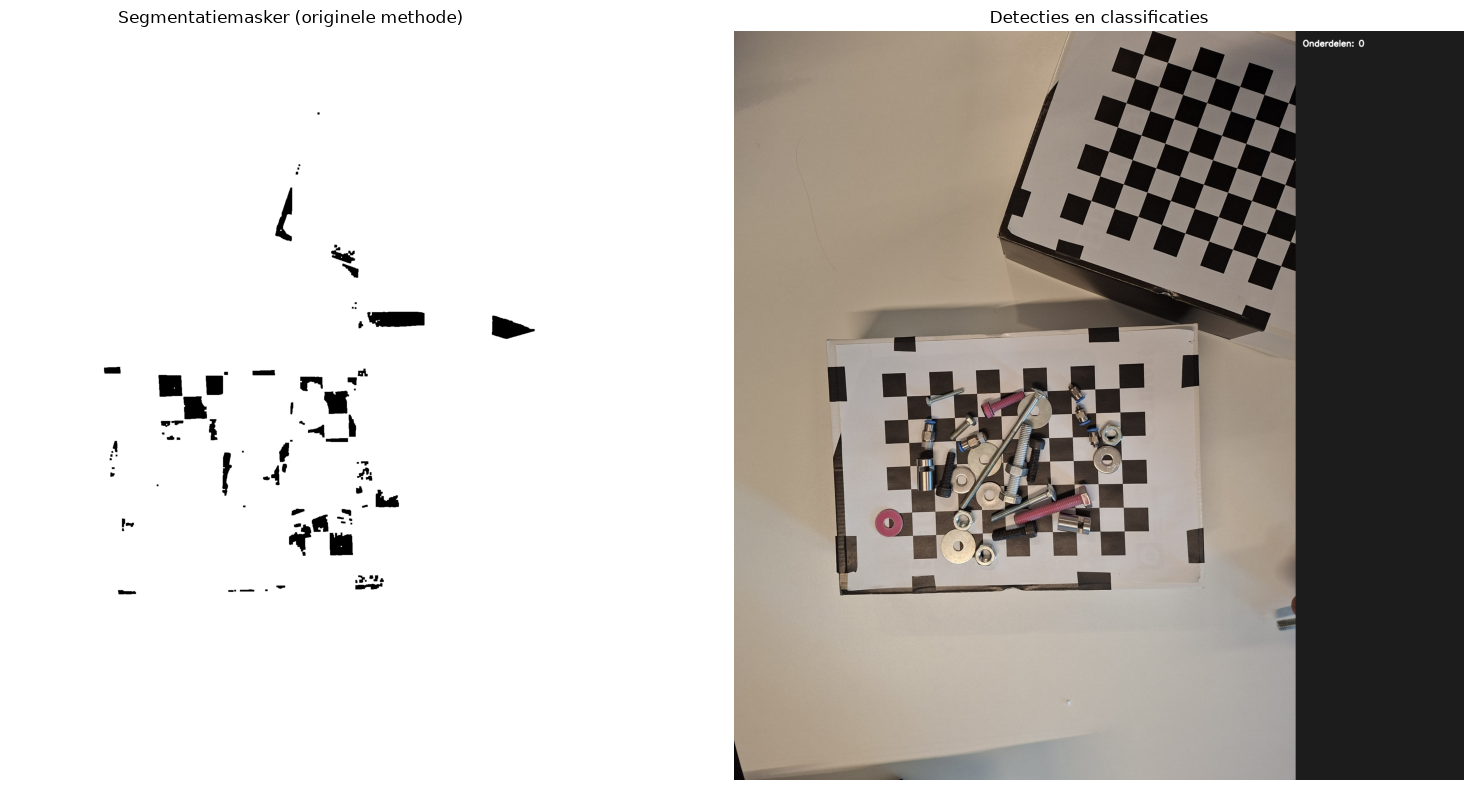

In [18]:
def analyseer_willekeurige_foto(afbeelding_pad=None, toon=True):
    if afbeelding_pad is None:
        if not fotos:
            raise FileNotFoundError(f'Geen afbeeldingen gevonden in {DATASET_ROOT.resolve()}')
        gekozen = random.choice(fotos)
    else:
        gekozen = Path(afbeelding_pad)
        if not gekozen.is_file():
            alternatieven = [p for p in fotos if p.name.lower() == gekozen.name.lower()]
            if not alternatieven:
                raise FileNotFoundError(f'Afbeelding niet gevonden: {gekozen}')
            gekozen = alternatieven[0]
    print('Gekozen testfoto:', gekozen)
    df, visualisatie, binair = detecteer_onderdelen(gekozen, PIXELS_PER_MM)
    RESULTATEN_DIR.mkdir(parents=True, exist_ok=True)
    vis_pad = RESULTATEN_DIR / f'{gekozen.stem}_visueel_klassiek.jpg'
    csv_pad = RESULTATEN_DIR / f'{gekozen.stem}_detecties_klassiek.csv'
    mask_pad = RESULTATEN_DIR / f'{gekozen.stem}_debug_masker.png'
    cv2.imwrite(str(vis_pad), visualisatie)
    cv2.imwrite(str(mask_pad), binair)
    df.to_csv(csv_pad, index=False)
    print('Aantal kandidaatdetecties:', len(df))
    print('Opgeslagen:', vis_pad, csv_pad, mask_pad, sep='\n  ')
    if not df.empty:
        display(df[['object_id','klasse','positie_x_mm','positie_y_mm','hoek_graden','lengte_mm','circulariteit']])
    if toon:
        fig, ax = plt.subplots(1,2,figsize=(17,8))
        ax[0].imshow(binair,cmap='gray'); ax[0].set_title('Segmentatiemasker (originele methode)')
        ax[1].imshow(cv2.cvtColor(visualisatie,cv2.COLOR_BGR2RGB)); ax[1].set_title('Detecties en classificaties')
        for a in ax: a.axis('off')
        plt.tight_layout(); plt.show()
    return df, visualisatie, binair

# Start met één foto. Verander AFBEELDING_PAD in blok 1 voor een specifieke foto.
df, visualisatie, masker = analyseer_willekeurige_foto(AFBEELDING_PAD)

## Optioneel: meerdere foto's testen

De onderstaande cel staat standaard uit. De oorspronkelijke methode gebruikt geen annotaties; de voorspelde klassennamen komen uit de geometrische regels en de namenlijst.

In [19]:
# Zet op True om maximaal 5 willekeurige foto's te verwerken.
TEST_MEERDERE = False
if TEST_MEERDERE:
    for pad in random.sample(fotos, min(5, len(fotos))):
        analyseer_willekeurige_foto(pad, toon=False)